# Control network: exploration

The **control** of the frozen-$W_{out}$ cog20 runs: 20 tasks, 150k steps, no rate or wiring
budget, `--freeze w_out --w-out-init fanin`. It is the reference the budgeted networks are
compared against — whatever structure it has came from the tasks alone, not from a cost.

`runs/moo_zoom/dale_all_rateray_woutfrozen_150k/control/` (the OB run's control is the same
network: same seed, same config, no budgets, so the two are identical).

Checkpoints carry `history` (per-task accuracy every 2000 steps, loss every step),
`task_variance` and `mean_rate` already computed, plus the final `metrics`.


## Setup

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from cmc.paths import MOO_ZOOM_RUNS_DIR
from cmc.task import rule_name

RUN   = MOO_ZOOM_RUNS_DIR / "dale_all_rateray_woutfrozen_150k"
POINT = "control"
SEEDS = [0, 1]

ckpts = {s: torch.load(RUN / POINT / f"seed_{s:02d}.pt", map_location="cpu",
                       weights_only=False) for s in SEEDS}
ck = ckpts[SEEDS[0]]
TASKS = list(ck["active_tasks"])

print(f"{RUN.name} / {POINT}")
print(f"  model      : {ck['model_type']}  {ck['model_kwargs']}")
print(f"  trained    : {ck['train_steps']:,} steps   freeze={ck['history']['freeze']}"
      f"   w_out_init={ck['model_kwargs']['w_out_init']}")
print(f"  budgets    : rate={ck['rate_budget']}  conn={ck['conn_budget']}   (control = none)")
print(f"  tasks      : {len(TASKS)}")
for s, c in ckpts.items():
    m = c["metrics"]
    print(f"  seed {s}     : min_task_acc {m['min_task_acc']:.3f}   mean_acc {m['mean_acc']:.3f}"
          f"   metabolic {m['metabolic_cost']:.3f}   wiring {m['wiring_cost']:.5f}"
          f"   conn_frac {m['conn_frac']:.3f}")

dale_all_rateray_woutfrozen_150k / control
  model      : dale  {'n_neurons': 256, 'frac_e': 0.8, 'g': 1.0, 'sigma_rec': 0.05, 'prune_eps': 0.0, 'w_out_init': 'fanin', 'seed': 0}
  trained    : 150,000 steps   freeze=['w_out']   w_out_init=fanin
  budgets    : rate=None  conn=None   (control = none)
  tasks      : 20
  seed 0     : min_task_acc 0.931   mean_acc 0.993   metabolic 4.266   wiring 0.03060   conn_frac 0.656
  seed 1     : min_task_acc 0.942   mean_acc 0.990   metabolic 2.528   wiring 0.04173   conn_frac 0.743


## 1. Accuracy over training

One panel per task family, one line per task, averaged over the two seeds. These are the
**training-time** evaluations: 64 trials, noise-free, every 2000 steps — noisier than the final
metrics, which use 10 eval seeds. The last panel shows the worst task and the mean across all 20,
per seed; `min_task_acc` is the project's task objective and the 0.6 line is the feasibility bar.


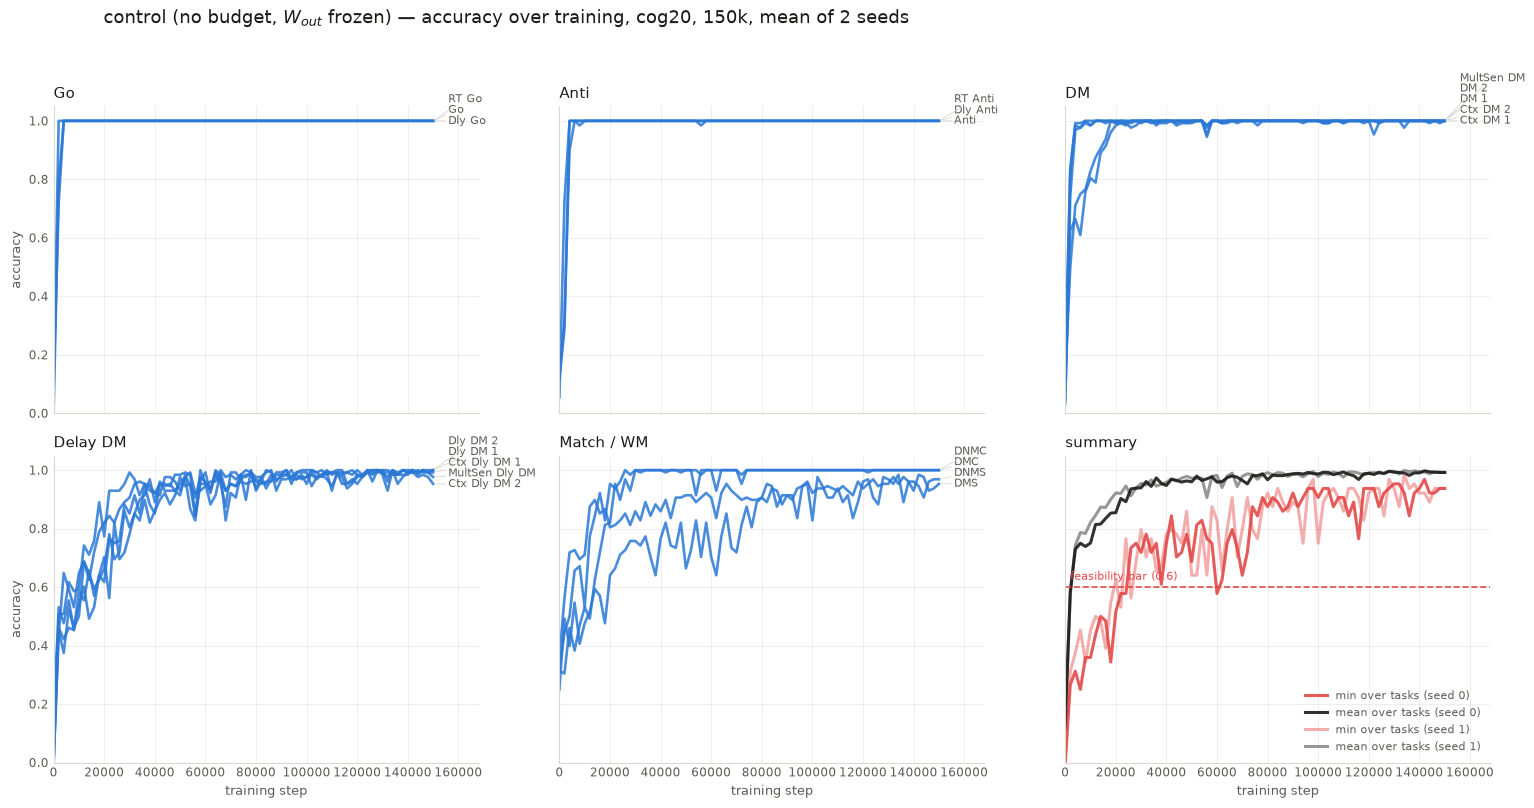

In [2]:
FAMILIES = [("Go",         ["fdgo", "reactgo", "delaygo"]),
            ("Anti",       ["fdanti", "reactanti", "delayanti"]),
            ("DM",         ["dm1", "dm2", "contextdm1", "contextdm2", "multidm"]),
            ("Delay DM",   ["delaydm1", "delaydm2", "contextdelaydm1",
                            "contextdelaydm2", "multidelaydm"]),
            ("Match / WM", ["dmsgo", "dmsnogo", "dmcgo", "dmcnogo"])]

INK, MUTED, ALERT, LINE = "#1a1a19", "#5c5b55", "#e34948", "#2a78d6"
steps = np.asarray(ck["history"]["eval_step"])

def acc(task):
    """Per-task accuracy over training, averaged over the seeds."""
    return np.mean([c["history"]["per_task"][task]["acc"] for c in ckpts.values()], axis=0)

fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.2), sharex=True, sharey=True)

def label_ends(ax, ends, x):
    """Right-edge labels, pushed apart in display space so they never overlap."""
    ax.set_xlim(0, x * 1.12); ax.set_ylim(0, 1.05)
    fig.canvas.draw()
    tr, inv = ax.transData.transform, ax.transData.inverted().transform
    prev, placed = -1e9, []
    for y, lab in sorted(ends):
        py = max(tr((x, y))[1], prev + 10.0); prev = py
        placed.append((y, lab, inv((0, py))[1]))
    for y, lab, ylab in placed:
        ax.annotate(lab, xy=(x, y), xytext=(x * 1.04, ylab), fontsize=7.6, color=MUTED,
                    va="center", annotation_clip=False,
                    arrowprops=dict(arrowstyle="-", color="#d8d7d0", lw=0.6,
                                    shrinkA=0, shrinkB=2))

for ax, (fam, tasks) in zip(axes.ravel(), FAMILIES):
    ends = []
    for t in tasks:
        y = acc(t)
        ax.plot(steps, y, lw=1.9, color=LINE, alpha=0.85)
        ends.append((y[-1], rule_name[t]))
    ax.set_title(fam, fontsize=11, color=INK, loc="left")
    label_ends(ax, ends, steps[-1])

# summary panel: worst task and mean, per seed
ax = axes.ravel()[5]
for s, c in ckpts.items():
    A = np.array([c["history"]["per_task"][t]["acc"] for t in TASKS])   # (20, n_eval)
    ax.plot(steps, A.min(axis=0), lw=2.2, color=ALERT, alpha=0.9 if s == 0 else 0.45,
            label=f"min over tasks (seed {s})")
    ax.plot(steps, A.mean(axis=0), lw=2.2, color=INK, alpha=0.9 if s == 0 else 0.45,
            label=f"mean over tasks (seed {s})")
ax.axhline(0.6, color=ALERT, ls="--", lw=1.2)
ax.text(2000, 0.625, "feasibility bar (0.6)", fontsize=8, color=ALERT)
ax.set_title("summary", fontsize=11, color=INK, loc="left")
ax.legend(fontsize=7.8, frameon=False, loc="lower right", labelcolor=MUTED)

for ax in axes.ravel():
    ax.set_ylim(0, 1.05)
    ax.set_xlim(0, steps[-1] * 1.12)
    ax.grid(True, alpha=0.22, lw=0.7)
    ax.tick_params(labelsize=8.5, colors=MUTED, length=0)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    for sp in ("left", "bottom"): ax.spines[sp].set_color("#d8d7d0")
for ax in axes[1]:  ax.set_xlabel("training step", fontsize=9.5, color=MUTED)
for ax in axes[:, 0]: ax.set_ylabel("accuracy", fontsize=9.5, color=MUTED)

fig.suptitle(f"{POINT} (no budget, $W_{{out}}$ frozen) — accuracy over training, cog20, 150k, "
             f"mean of {len(SEEDS)} seeds", fontsize=13, color=INK, x=0.07, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()